<a href="https://colab.research.google.com/github/Shyam057/Online-Shoppers-Purchase-Prediction/blob/main/Online_Shoppers_Purchase_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git config --global user.name "Shyam057"
!git config --global user.email "shyambhattarai057@gmail.com"

In [12]:
from google.colab import userdata
import subprocess
import os

token = userdata.get('GITHUB_TOKEN')

repo_url = "https://github.com/Shyam057/Online-Shoppers-Purchase-Prediction.git"

auth_url = repo_url.replace(
    "https://",
    f"https://x-access-token:{token}@"
)

subprocess.run(
    ["git", "remote", "set-url", "origin", auth_url],
    check=True
)

subprocess.run(
    ["git", "push", "-u", "origin", "main"],
    check=True
)

CompletedProcess(args=['git', 'push', '-u', 'origin', 'main'], returncode=0)

##**Online Shoppers Purchasing Intention Prediction Using Machine Learning**

**Course:** CS634-BX1 Machine Learning, Fall 2026

**Assignment:** Your Choice of Second ML App

**Contributors:**

*   Shyam Kumar Bhattarai
*   Bikram Sitaula





# Online Shoppers Purchasing Intention Prediction Using Machine Learning

## 1. Introduction

Online shopping has become very popular. Many people visit online shopping websites to explore products, compare prices, and search for information. However, not every visitor makes a purchase.

For an online business, understanding customer behavior is important. If a business can identify visitors who are more likely to purchase products, it can improve its marketing strategies and customer experience.

In this project, we use machine learning techniques to predict whether an online shopping session will result in a purchase.

We use the Online Shoppers Purchasing Intention dataset from the UCI Machine Learning Repository. The dataset contains information about visitor behavior, browsing time, page visits, and other session details.

## 2. Project Objectives

The main objectives of this project are:

- Understand and analyze online shopping behavior.
- Prepare the dataset for machine learning.
- Select important features from the dataset.
- Apply PCA for dimensionality reduction.
- Train different machine learning classification models.
- Tune model hyperparameters to improve performance.
- Compare the models using different evaluation metrics.
- Find the best-performing model for predicting purchase intention.

## 3. Expected Outcome

At the end of this project, we aim to develop a machine learning model that can predict whether an online shopping visitor will complete a purchase.

We will also compare different machine learning algorithms and investigate how feature selection, dimensionality reduction, and hyperparameter tuning affect model performance.

## 4. Dataset Information

Dataset Name: Online Shoppers Purchasing Intention Dataset

Source: UCI Machine Learning Repository

Total Records: 12,330

Input Features: 17

Target Variable: Revenue

Problem Type: Binary Classification


In [ ]:
#dataset library
!pip -q install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline


## 5. Dataset Loading

In this section, we load the online shopping dataset from the UCI Machine Learning Repository.

Each row represents one online shopping session. The dataset contains information about the visitor's browsing activities and whether the session resulted in a purchase.

We will first load the dataset and check its structure.


In [ ]:
from ucimlrepo import fetch_ucirepo

shop_dataset=fetch_ucirepo(id=468)

shop_features=shop_dataset.data.features
shop_target=shop_dataset.data.targets

# combine the features and target into one DataFrame
df=pd.concat([shop_features, shop_target], axis=1)

# save the original dataset
df.to_csv('online_shoppers_intention.csv', index=False)

print("Dataset Loaded successfully!")
print("Dataset shape: ", df.shape)

Dataset Loaded successfully!
Dataset shape:  (12330, 18)


## 6. Understanding the Dataset

Before training machine learning models, we need to understand the dataset.

In this section, we will check the first few records, column names, data types, missing values, and target distribution.

In [ ]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [ ]:
# count missiong values in each column

df.isnull().sum()

,0
Administrative,0
Administrative_Duration,0
Informational,0
Informational_Duration,0
ProductRelated,0
ProductRelated_Duration,0
BounceRates,0
ExitRates,0
PageValues,0
SpecialDay,0


In [ ]:
#check duplicate rows
df.duplicated().sum()

np.int64(125)

In [ ]:
#count purchase and non-purchase session
purchase_count = df["Revenue"].value_counts()
print(purchase_count)

# display the percentage of each class
purchase_percentage = df["Revenue"].value_counts(normalize=True)*100
print(f"\nPurchase distribution (%): {purchase_percentage}")


Revenue
False    10422
True      1908
Name: count, dtype: int64

Purchase distribution (%): Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64



## 7. Data Cleaning

We will check the quality of the dataset before training the models.

Our dataset does not contain missing values. However, we found 125 duplicate records.

We will remove exact duplicate rows to avoid giving repeated records unnecessary influence during model training.


In [ ]:
df=df.drop_duplicates().copy()

df=df.reset_index(drop=True)

df.duplicated().sum()

np.int64(0)

In [ ]:
df.shape

(12205, 18)


## 8. Exploratory Data Analysis

Exploratory Data Analysis helps us understand the patterns and relationships in the dataset.

We will visualize purchase distribution, visitor types, monthly shopping behavior, and numerical features.

These visualizations will help us understand customer behavior before building machine learning models.


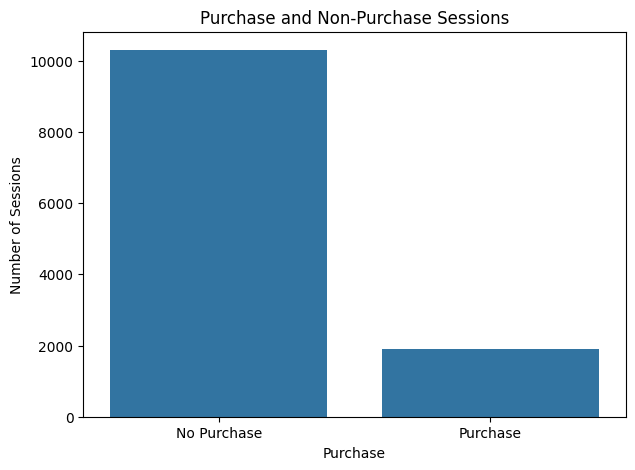

In [ ]:
# Count purchase and non-purchase sessions
purchase_count = df["Revenue"].value_counts()

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Revenue")

plt.title("Purchase and Non-Purchase Sessions")
plt.xlabel("Purchase")
plt.ylabel("Number of Sessions")
plt.xticks([0, 1], ["No Purchase", "Purchase"])

plt.show()

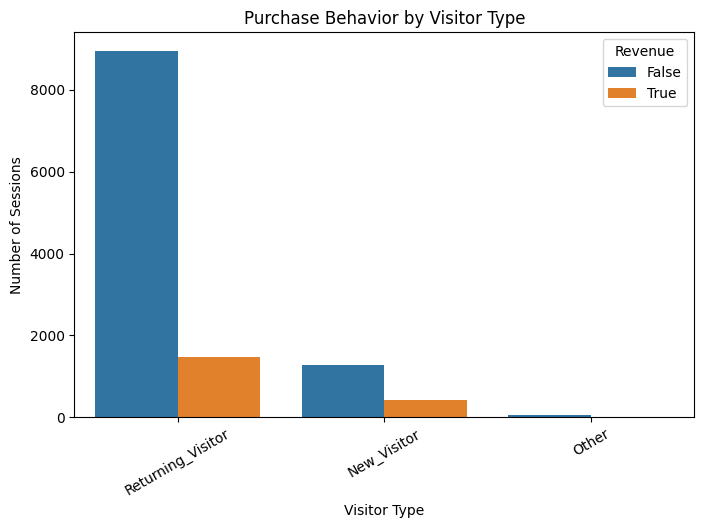

In [ ]:
#Purchase behavior by visitor type
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="VisitorType",
    hue="Revenue"
)

plt.title("Purchase Behavior by Visitor Type")
plt.xlabel("Visitor Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)

plt.show()

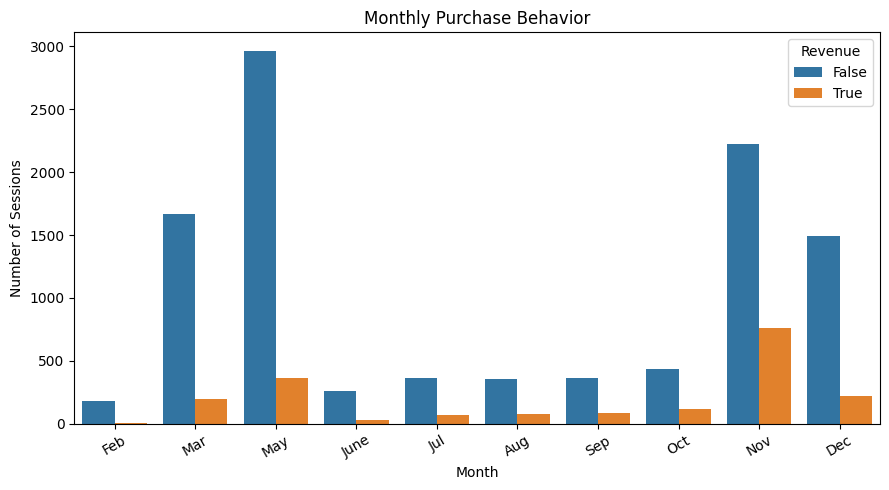

In [ ]:
# Monthly purchase behavior

month_order = [
    "Feb", "Mar", "May", "June", "Jul",
    "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Month",
    hue="Revenue",
    order=month_order
)

plt.title("Monthly Purchase Behavior")
plt.xlabel("Month")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

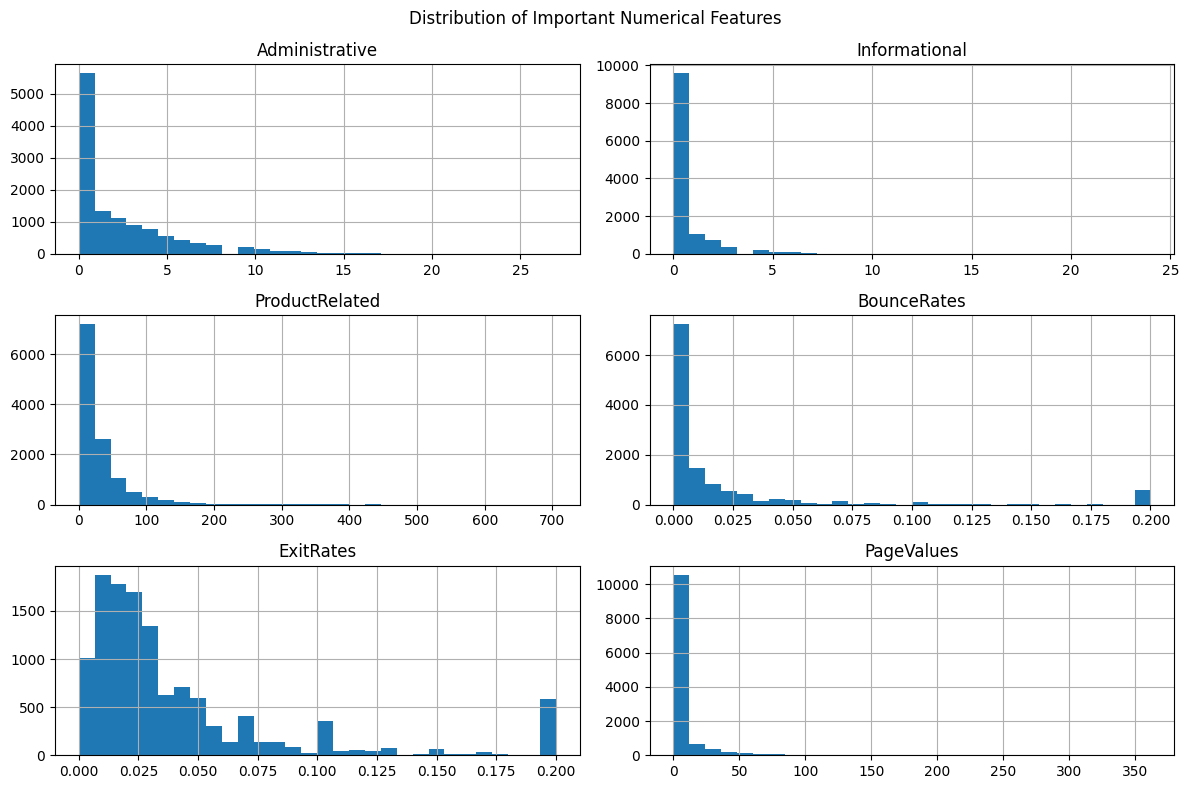

In [ ]:
#distribution of important numerical features

important_columns=[
    "Administrative", "Informational", "ProductRelated", "BounceRates", "ExitRates", "PageValues"
]
df[important_columns].hist(figsize=(12, 8),bins=30)
plt.suptitle("Distribution of Important Numerical Features")
plt.tight_layout()
plt.show()

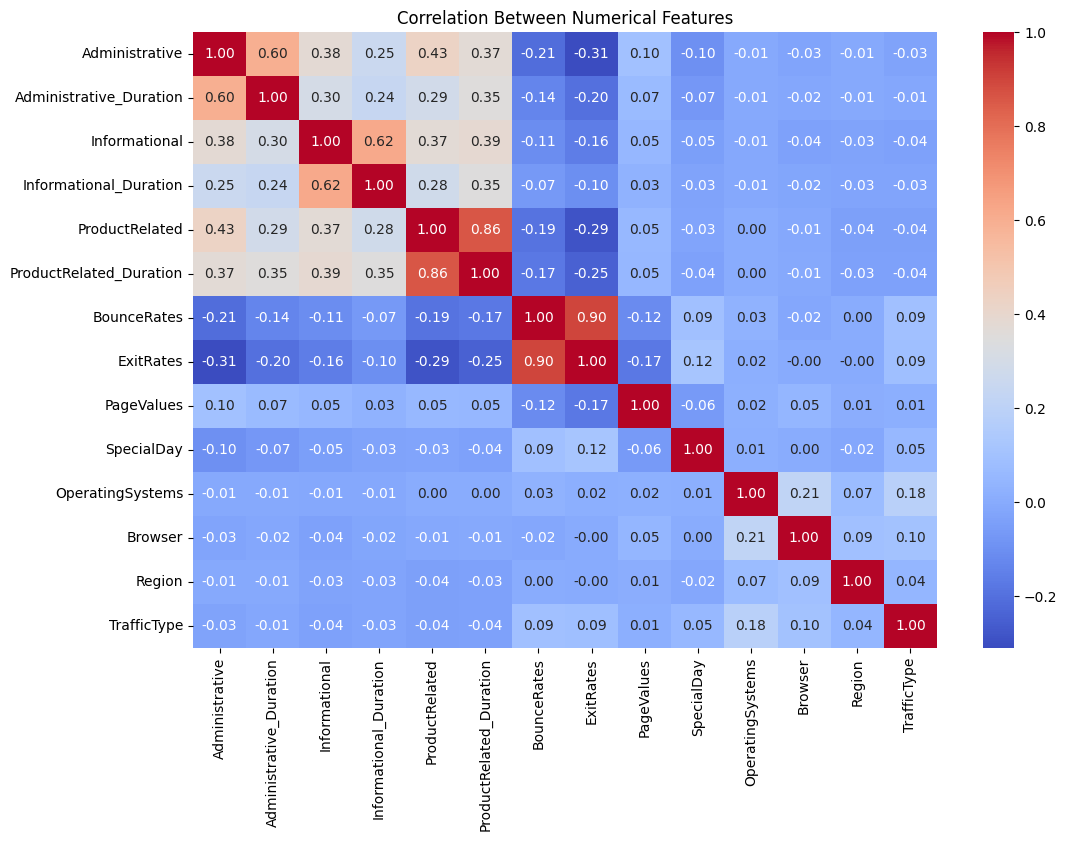

In [ ]:
#Numerical columns for correlation analysis
num_data=df.select_dtypes(include=["int64","float64"])

plt.figure(figsize=(12,8))

sns.heatmap(num_data.corr(), annot=True, cmap="coolwarm",fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.show()



## 9. Data Preprocessing

Machine learning algorithms require numerical input.

Our dataset contains categorical columns such as Month and VisitorType. We will convert these columns into numerical values using OneHotEncoder.

We will also scale numerical features using StandardScaler so that features with different value ranges can be used together.

Finally, we will separate the input features and target variable and divide the data into training and testing sets.


In [ ]:
X=df.drop("Revenue",axis=1)
y=df["Revenue"].astype(int)

print("Input features shape: ", X.shape)
print("Target variable shape: ", y.shape)

Input features shape:  (12205, 17)
Target variable shape:  (12205,)


In [ ]:
# Numerical columns
number_columns = [
    "Administrative",
    "Administrative_Duration",
    "Informational",
    "Informational_Duration",
    "ProductRelated",
    "ProductRelated_Duration",
    "BounceRates",
    "ExitRates",
    "PageValues",
    "SpecialDay"
]

# Categorical columns
category_columns = [
    "Month",
    "OperatingSystems",
    "Browser",
    "Region",
    "TrafficType",
    "VisitorType",
    "Weekend"
]

print("Number of numerical features:", len(number_columns))
print("Number of categorical features:", len(category_columns))

Number of numerical features: 10
Number of categorical features: 7


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#preprocessing for numerical and categorical columns
preprocessor=ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), number_columns),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), category_columns)
    ]
)
print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


In [ ]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("X_train shape: ", X_train.shape)
print("X_test shape: ", X_test.shape)

print("\n Training target distribution:")
print(y_train.value_counts(normalize=True))

print("\n Testing target distribution:")
print(y_test.value_counts(normalize=True))

X_train shape:  (9764, 17)
X_test shape:  (2441, 17)

 Training target distribution:
Revenue
0    0.843712
1    0.156288
Name: proportion, dtype: float64

 Testing target distribution:
Revenue
0    0.843507
1    0.156493
Name: proportion, dtype: float64



## 10. Feature Selection and Dimensionality Reduction

We will investigate whether reducing the number of features can improve machine learning performance.

First, we will use all available features as a baseline.

Next, we will use SelectKBest to select the most important features based on their statistical relationship with the target variable.

Finally, we will apply Principal Component Analysis (PCA) to reduce the number of dimensions while retaining 95% of the explained variance.

We will compare the results of these approaches with the original feature set.


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.decomposition import PCA

In [ ]:
#splitting the training data into training and validation sets

X_train_part,X_val,y_train_part,y_val=train_test_split(X_train,y_train,test_size=0.25,random_state=42,stratify=y_train)

print("Model training data:", X_train_part.shape)
print("Validation data:",X_val.shape)
print("Final test data:", X_test.shape)

Model training data: (7323, 17)
Validation data: (2441, 17)
Final test data: (2441, 17)


In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# create the machine learning models
models={
    "SGD":SGDClassifier(max_iter=2000,class_weight="balanced",random_state=42),
    "SVC":SVC(class_weight="balanced",random_state=42),
    "DecisionTree":DecisionTreeClassifier(class_weight="balanced",random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150,class_weight="balanced",random_state=42,n_jobs=-1),
    "KNN":KNeighborsClassifier(n_neighbors=7)
    }
print("The 5 machine learning models are created successfully")

The 5 machine learning models are created successfully


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.metrics import(accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score)

# defines the 3 features approaches
feature_methods={
    "Original Features": "passthrough",
    "selectKBest": SelectKBest(score_func=f_classif, k=10),
    "PCA": PCA(n_components=0.95, random_state=42)
}
results=[]
trained_models={}

# Train each model with each feature approach
for feature_name, feature_method in feature_methods.items():
  for model_name, model in models.items():
    print(f"Training {model_name} with {feature_name} features")

    #create the complete pipeline
    model_pipeline=Pipeline([
        ("Preprocessing",preprocessor),
        ("Feature Selection",feature_method),
        ("classifier",model)
                             ])
    model_pipeline.fit(X_train_part,y_train_part)

    #evaluate the model on the validation set
    y_pred=model_pipeline.predict(X_val)

    #get the prediction scores for ROC-AUC
    if hasattr(model_pipeline,"predict_proba"):
      y_pred_proba=model_pipeline.predict_proba(X_val)[:,1]
    else:
      y_pred_proba=model_pipeline.decision_function(X_val)

    #calculate the performance matrix
    results.append({
        "Model":model_name,
        "Feature Approach":feature_name,
        "Accuracy":accuracy_score(y_val,y_pred),
        "Balanced Accuracy":balanced_accuracy_score(y_val,y_pred),
        "Precision":precision_score(y_val,y_pred),
        "Recall":recall_score(y_val,y_pred),
        "F1 Score":f1_score(y_val,y_pred),
        "ROC-AUC":roc_auc_score(y_val,y_pred_proba)
    })
    trained_models[model_name,feature_name]=model_pipeline

# Create and sort the model comparison table
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

# Display all model results
display(results_df.round(4))


Training SGD with Original Features features
Training SVC with Original Features features
Training DecisionTree with Original Features features
Training Random Forest with Original Features features
Training KNN with Original Features features
Training SGD with selectKBest features
Training SVC with selectKBest features
Training DecisionTree with selectKBest features
Training Random Forest with selectKBest features
Training KNN with selectKBest features
Training SGD with PCA features
Training SVC with PCA features
Training DecisionTree with PCA features
Training Random Forest with PCA features
Training KNN with PCA features


,Model,Feature Approach,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,SVC,PCA,0.8730,0.8167,0.5726,0.7349,0.6437,0.8889
1,SVC,Original Features,0.8718,0.8139,0.5697,0.7297,0.6398,0.8928
2,SVC,selectKBest,0.8607,0.8212,0.5379,0.7638,0.6312,0.8642
3,Random Forest,selectKBest,0.8935,0.7625,0.6921,0.5722,0.6264,0.9002
4,Random Forest,Original Features,0.8943,0.7395,0.7286,0.5144,0.6031,0.9110
5,SGD,Original Features,0.8410,0.8128,0.4941,0.7717,0.6025,0.8713
6,SGD,PCA,0.8435,0.8014,0.4991,0.7402,0.5962,0.8542
7,SGD,selectKBest,0.8431,0.7990,0.4982,0.7349,0.5938,0.8720
8,KNN,selectKBest,0.8800,0.7235,0.6517,0.4961,0.5633,0.8502
9,DecisionTree,Original Features,0.8574,0.7412,0.5409,0.5722,0.5561,0.7412


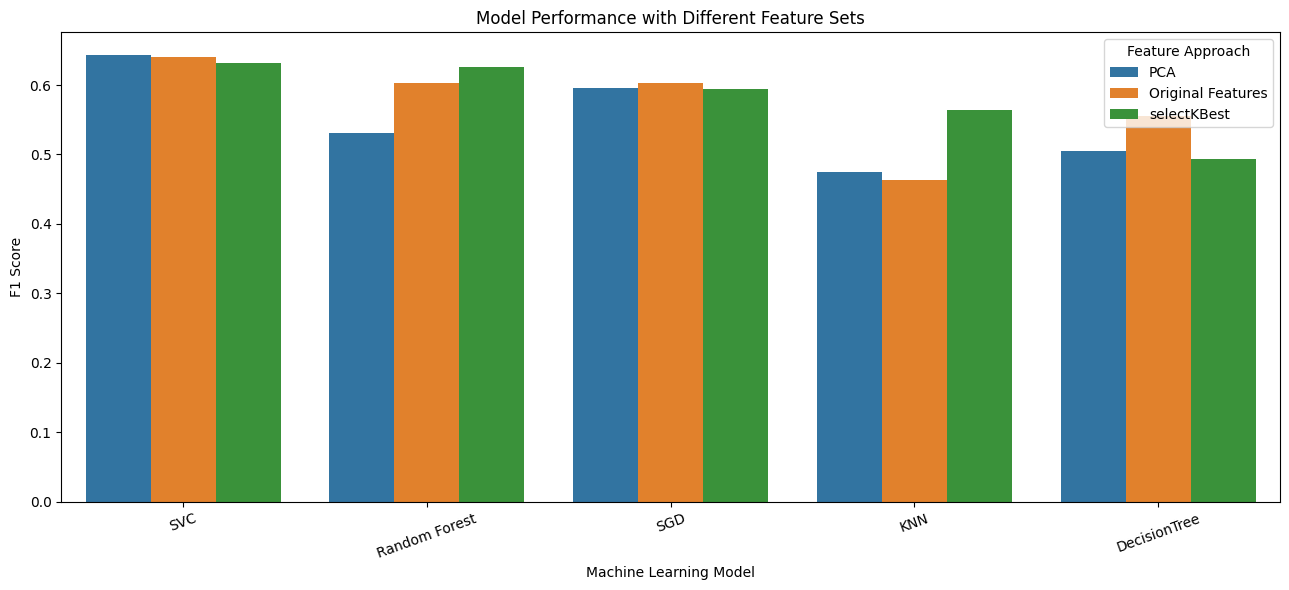

In [ ]:
plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score",
    hue="Feature Approach"
)

plt.title("Model Performance with Different Feature Sets")
plt.ylabel("F1 Score")
plt.xlabel("Machine Learning Model")
plt.xticks(rotation=20)
plt.tight_layout()

plt.show()

In [ ]:
best_result = results_df.iloc[0]

print("Best model:", best_result["Model"])
print("Feature approach:", best_result["Feature Approach"])
print("Accuracy:", round(best_result["Accuracy"], 4))
print("F1 Score:", round(best_result["F1 Score"], 4))
print("ROC AUC:", round(best_result["ROC-AUC"], 4))

Best model: SVC
Feature approach: Original Features
Accuracy: 0.8718
F1 Score: 0.6398
ROC AUC: 0.8928



## 11. Hyperparameter Tuning

Hyperparameters are settings that control how a machine learning model learns.

In this section, we will use GridSearchCV to find better hyperparameter values for our selected model.

We will compare the default model with the tuned model to understand whether hyperparameter tuning improves performance.

We will use cross-validation to make the model selection more reliable.


In [ ]:
from sklearn.model_selection import GridSearchCV

# get the best model and feature approach
best_model_name=best_result["Model"]
best_feature_name=best_result["Feature Approach"]

#get the selected model
selected_model=models[best_model_name]

#select the feature reduction method
selected_feature_method=feature_methods[best_feature_name]

#create the complete pipeline for tuning
tuning_pipeline=Pipeline([
    ("Preprocessing",preprocessor),
    ("Feature Selection",selected_feature_method),
    ("classifier",selected_model)
])

# Define the parameter grids
param_grid={
    "SGD":{
        "classifier__alpha":[0.0001,0.001,0.01,0.1],
        "classifier__loss":["hinge","log_loss"],
    },
    "SVC":{
        "classifier__C":[0.01,0.1,1,10,100],
        "classifier__kernel":["linear","rbf"],
        "classifier__class_weight":["balanced",None]
    },
    "DecisionTree":{
        "classifier__max_depth":[None,5,10,15],
        "classifier__min_samples_split":[2,5,10],
    },
    "Random Forest":{
        "classifier__n_estimators":[100,200],
        "classifier__max_depth":[10,20,None],
        "classifier__min_samples_split":[2,5]
    },
    "KNN":{
        "classifier__n_neighbors":[3,5,7],
        "classifier__weights":["uniform","distance"]
    }
}

grid_search=GridSearchCV(
    estimator=tuning_pipeline,
    param_grid=param_grid[best_model_name],
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)
grid_search.fit(X_train,y_train)

print(f"Best parameters:{grid_search.best_params_}")
print(f"Best score:{grid_search.best_score_:.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters:{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__kernel': 'linear'}
Best score:0.6462



## 12. Final Model Evaluation

After comparing the different machine learning algorithms and tuning the selected model, we will evaluate its performance using the test dataset.

We will use accuracy, precision, recall, F1-score, balanced accuracy, and ROC-AUC.

We will also display the confusion matrix to understand the correct and incorrect predictions made by the model.


In [ ]:
from sklearn.metrics import classification_report

# Train the selected default model using all training data
default_final_model = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_reduction", selected_feature_method),
    ("classifier", selected_model)
])

default_final_model.fit(X_train, y_train)

# Get predictions from both models
default_predictions = default_final_model.predict(X_test)
tuned_predictions = grid_search.best_estimator_.predict(X_test)

# Compare final model performance
final_results = []

for model_name, predictions in [
    ("Default Model", default_predictions),
    ("Tuned Model", tuned_predictions)
]:

    final_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Balanced Accuracy": balanced_accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

final_results_df = pd.DataFrame(final_results)

final_results_df.round(4)

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1 Score
0,Default Model,0.8689,0.8285,0.5589,0.7696,0.6476
1,Tuned Model,0.8763,0.8307,0.5794,0.7644,0.6591


In [ ]:
# Check how many features PCA selected
best_validation_pipeline = trained_models[
    (best_result["Model"], best_result["Feature Approach"])
]

original_feature_count = best_validation_pipeline.named_steps[
    "Preprocessing"
].transform(X_train_part).shape[1]

pca_component_count = best_validation_pipeline.named_steps[
    "Feature Selection"
].n_components_

print("Features after preprocessing:", original_feature_count)
print("Features after PCA:", pca_component_count)
print(
    "Explained variance:",
    round(
        best_validation_pipeline.named_steps[
            "Feature Selection"
        ].explained_variance_ratio_.sum(),
        4
    )
)

AttributeError: 'str' object has no attribute 'n_components_'

In [ ]:
print("Classification Report for Tuned Model")

print(
    classification_report(
        y_test,
        tuned_predictions,
        target_names=["No Purchase", "Purchase"],
        zero_division=0
    )
)

In [ ]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, tuned_predictions)

plt.figure(figsize=(7, 5))

sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Purchase", "Purchase"],
    yticklabels=["No Purchase", "Purchase"]
)

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

In [ ]:
from sklearn.metrics import roc_curve, auc

# Get prediction scores using decision_function since probability=False on the tuned SVC
if hasattr(grid_search.best_estimator_, "predict_proba"):
    try:
        test_probabilities = grid_search.best_estimator_.predict_proba(X_test)[:, 1]
    except AttributeError:
        test_probabilities = grid_search.best_estimator_.decision_function(X_test)
else:
    test_probabilities = grid_search.best_estimator_.decision_function(X_test)

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, test_probabilities)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ROC Curve (AUC = {roc_auc:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Final Model")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

In [ ]:
import joblib

# Save the tuned model
joblib.dump(
    grid_search.best_estimator_,
    "online_shopping_purchase_model.pkl"
)

print("Final model saved successfully!")


## 13. Conclusion

In this project, we developed a machine learning model to predict whether an online shopping session will result in a purchase.

We started by exploring and cleaning the dataset. We found 125 duplicate records and removed them. We also confirmed that the dataset did not contain missing values.

We applied data preprocessing techniques, including feature scaling and one-hot encoding. We then used SelectKBest and PCA to investigate dimensionality reduction.

We trained five machine learning algorithms: SGDClassifier, SVM, Decision Tree, Random Forest, and KNN.

Based on our validation results, SVM with PCA achieved the best performance. We then used GridSearchCV to find better hyperparameters.

The tuned SVM model achieved an accuracy of 87.67% and an F1-score of 65.91% on the test dataset.

The results show that hyperparameter tuning improved the performance compared with the default model.

However, the model still makes some incorrect predictions, especially when identifying customers who will complete a purchase.

### Future Improvements

- Test the model without PageValues to investigate possible information leakage.
- Collect more recent online shopping data.
- Test different feature selection methods.
- Improve the prediction of purchase sessions.
- Develop a web application to demonstrate the model.
